# Figure 5

In [1]:
import os
import sys
sys.path.insert(0, "../lib")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
plt.rcParams["pdf.fonttype"] = 42
plt.rcParams["ps.fonttype"] = 42

FIG = "../figures/Fig5"
os.makedirs(FIG, exist_ok=True)
all_df = pd.read_parquet("../data/sparks/all_antenna_traces.parquet")
sessions = pd.read_csv("../data/sparks/sessions.csv")          # one row per pupa: figure label (Ant #11-14)
ANALYZED = sessions.animal_session.tolist()
ANT = dict(zip(sessions.animal_session, sessions.ant))
SIDE_COLORS = {"left": "#eb6834", "right": "#4c9be8"}
sessions[["age", "ant"]]

,age,ant
0,P16,Ant #11
1,P16,Ant #12
2,P17,Ant #13
3,P17,Ant #14


## Panel D and Figure S3

The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


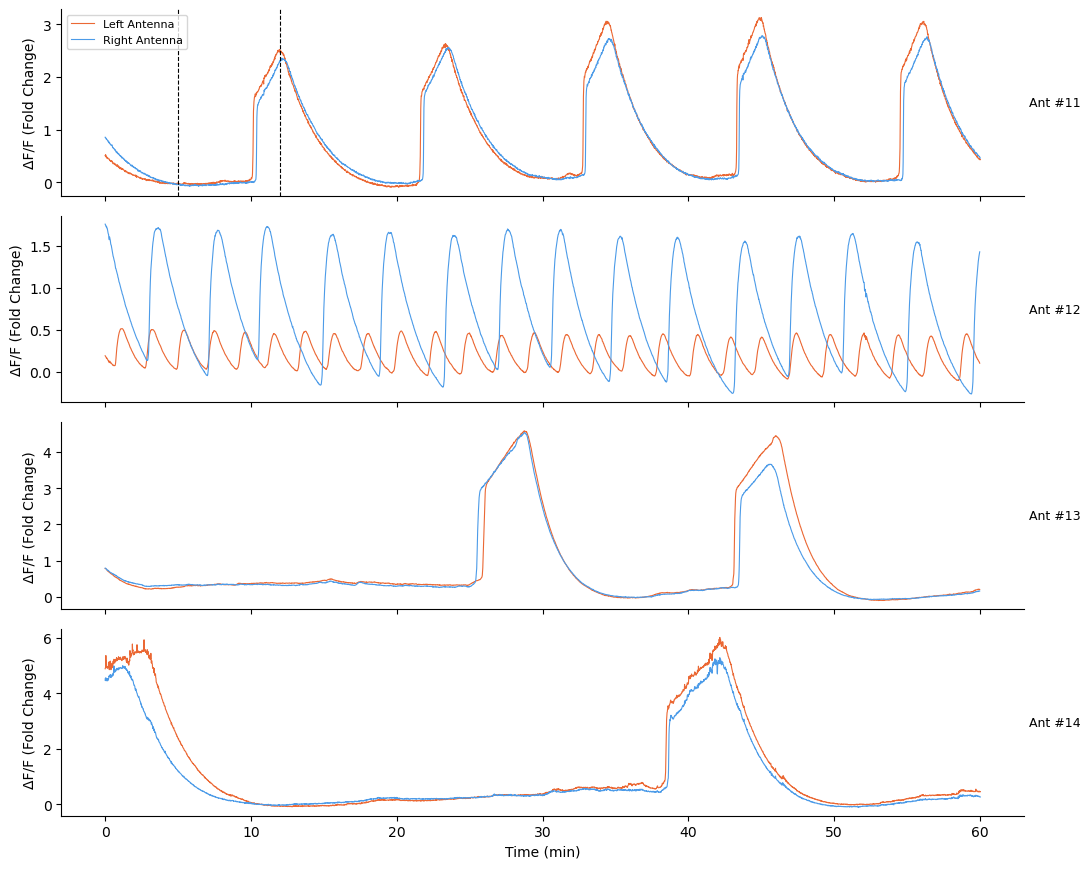

In [2]:
fig, axes = plt.subplots(len(ANALYZED), 1, figsize=(11, 2.2 * len(ANALYZED)), sharex=True)
for ax, sess in zip(axes, ANALYZED):
    d = all_df[all_df.animal_session == sess]
    for side in ["left", "right"]:
        ax.plot(d.time_s / 60, d[f"{side}_dff"], color=SIDE_COLORS[side], lw=0.8, label=f"{side.capitalize()} Antenna")
    if sess == ANALYZED[0]:
        for t in (5, 12):
            ax.axvline(t, color="black", ls="--", lw=0.8)
    ax.set_ylabel("ΔF/F (Fold Change)"); ax.text(1.005, 0.5, ANT[sess], transform=ax.transAxes, fontsize=9, va="center")
    ax.spines[["top", "right"]].set_visible(False)
axes[0].legend(fontsize=8, loc="upper left"); axes[-1].set_xlabel("Time (min)")
plt.tight_layout()
plt.savefig(f"{FIG}/Fig5D_FigS3_antenna_traces.pdf", bbox_inches="tight"); plt.savefig(f"{FIG}/Fig5D_FigS3_antenna_traces.eps", bbox_inches="tight")

## Panel E

,ant,side,n_events,n_reliable_peaks,n_intervals,mean_interpeak_s
0,Ant #11,left,5,5,4,662.728868
1,Ant #11,right,6,5,4,663.729592
2,Ant #12,left,28,26,25,133.258171
3,Ant #12,right,16,14,13,240.263531
4,Ant #13,left,2,2,1,1034.141013
5,Ant #13,right,2,2,1,1008.137468
6,Ant #14,left,2,2,1,2369.712284
7,Ant #14,right,2,2,1,2457.775917


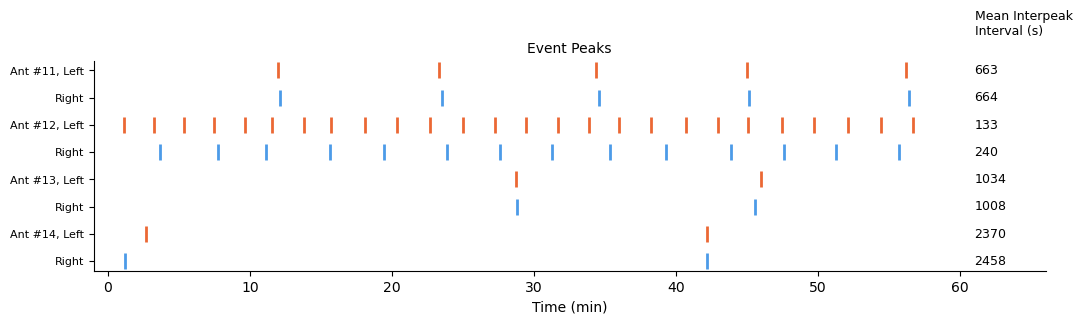

In [3]:
FRAC, MIN_DUR_S = 0.30, 10.0

def detect_events_antenna(tr, fi, frac=FRAC, min_dur_s=MIN_DUR_S):
    thresh = tr.min() + frac * (tr.max() - tr.min())
    above = tr > thresh
    d = np.diff(above.astype(int))
    starts = list(np.flatnonzero(d == 1) + 1); ends = list(np.flatnonzero(d == -1) + 1)
    if above[0]: starts = [0] + starts
    if above[-1]: ends = ends + [len(tr)]
    ev = []
    for s, e in zip(starts, ends):
        if (e - s) * fi < min_dur_s:
            continue
        ev.append({"onset_s": s * fi, "offset_s": (e - 1) * fi, "duration_s": (e - s) * fi,
                   "peak_dff": float(tr[s:e].max()), "truncated_start": s == 0, "truncated_end": e == len(tr)})
    return ev, thresh

event_rows, peak_data, interval_rows = [], {}, []
for sess in ANALYZED:
    d = all_df[all_df.animal_session == sess]; fi = np.diff(d.time_s.values[:2])[0]
    for side in ["left", "right"]:
        tr = d[f"{side}_dff"].to_numpy()
        ev, thresh = detect_events_antenna(tr, fi)
        peaks = []
        for e in ev:
            i0, i1 = int(e["onset_s"] / fi), int(e["offset_s"] / fi) + 1
            k = i0 + int(np.argmax(tr[i0:i1]))
            reliable = not (e["truncated_start"] and k <= i0 + 2) and not e["truncated_end"]
            peaks.append((k * fi, reliable))
            event_rows.append({"ant": ANT[sess], "session": sess, "side": side, **e, "peak_t_s": k * fi, "peak_reliable": reliable})
        peak_data[(sess, side)] = peaks
        pt = np.sort([t for t, ok in peaks if ok]); iei = np.diff(pt)
        interval_rows.append({"ant": ANT[sess], "side": side, "n_events": len(ev), "n_reliable_peaks": len(pt),
                              "n_intervals": len(iei), "mean_interpeak_s": iei.mean() if len(iei) else np.nan})
events = pd.DataFrame(event_rows).drop(columns="session"); intervals = pd.DataFrame(interval_rows)
events.to_csv("../data/sparks/antenna_events.csv", index=False)
intervals.to_csv("../data/sparks/interpeak_intervals.csv", index=False)

fig, ax = plt.subplots(figsize=(11, 3.4))
ylab = []
for i, (sess, side) in enumerate([(s, sd) for s in ANALYZED for sd in ["left", "right"]]):
    for t, ok in peak_data[(sess, side)]:
        if ok:
            ax.plot(t / 60, i, "|", color=SIDE_COLORS[side], ms=12, mew=2)
    m = intervals[(intervals.ant == ANT[sess]) & (intervals.side == side)].mean_interpeak_s.iloc[0]
    ax.text(61, i, f"{m:.0f}" if np.isfinite(m) else "n/a", va="center", fontsize=9)
    ylab.append(f"{ANT[sess]}, {side.capitalize()}" if side == "left" else side.capitalize())
ax.text(61, -1.2, "Mean Interpeak\nInterval (s)", fontsize=9, va="bottom")
ax.set_yticks(range(len(ylab))); ax.set_yticklabels(ylab, fontsize=8); ax.invert_yaxis()
ax.set_xlim(-1, 66); ax.set_xlabel("Time (min)"); ax.set_title("Event Peaks", fontsize=10)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.savefig(f"{FIG}/Fig5E_event_peaks_raster.pdf", bbox_inches="tight"); plt.savefig(f"{FIG}/Fig5E_event_peaks_raster.eps", bbox_inches="tight")
intervals

## Panel F

The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


,ant,peak_r,peak_lag_s
0,Ant #11,0.996,12.009
1,Ant #12,0.150,72.010
2,Ant #13,0.963,-10.001
3,Ant #14,0.977,-5.004


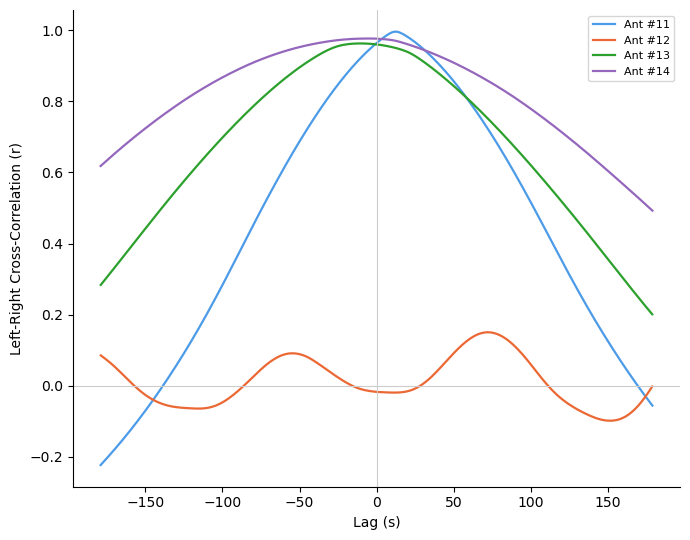

In [4]:
def xcorr(l, r, max_lag):
    lags = np.arange(-max_lag, max_lag + 1)
    cc = [np.corrcoef(l[max(0, -k):len(l) - max(0, k)], r[max(0, k):len(r) - max(0, -k)])[0, 1] for k in lags]
    return lags, np.array(cc)

palette = dict(zip(ANALYZED, ["#4c9be8", "#eb6834", "#2ca02c", "#9467bd"]))
fig, ax = plt.subplots(figsize=(7, 5.5))
xc_rows = []
for sess in ANALYZED:
    d = all_df[all_df.animal_session == sess]; fi = np.diff(d.time_s.values[:2])[0]
    lags, cc = xcorr(d.left_dff.to_numpy(), d.right_dff.to_numpy(), int(180 / fi))
    k = lags[np.argmax(cc)] * fi
    ax.plot(lags * fi, cc, color=palette[sess], lw=1.6, label=ANT[sess])
    xc_rows.append({"ant": ANT[sess], "peak_r": cc.max(), "peak_lag_s": k})
ax.axvline(0, color="0.8", lw=0.8); ax.axhline(0, color="0.8", lw=0.8)
ax.set_xlabel("Lag (s)"); ax.set_ylabel("Left-Right Cross-Correlation (r)")
ax.legend(fontsize=8); ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout()
plt.savefig(f"{FIG}/Fig5F_xcorr.pdf", bbox_inches="tight"); plt.savefig(f"{FIG}/Fig5F_xcorr.eps", bbox_inches="tight")
pd.DataFrame(xc_rows).round(3)